# Exploratory Data Analysis: Peaks
In this notebook, I investigate the Peaks dataset and assess its suitability for a data warehouse following the Medallion architecture. The raw data serves as the Bronze layer, forming the basis for creating a Silver-layer Star schema of fact and dimension tables.

The main points of emphasis are:
- __data cleanliness:__ data type alignment, missing values, distributions
- __adherence to normal forms:__ key integrity, atomicity, transitive dependencies
- __feature selection:__ deciding which columns are of interest for a subject-oriented data warehouse

The aim is to come up with a feasible data warehouse schema, uncover potential weaknesses in the data, and identify required transformations. A structured and tested ETL pipeline will be built based on the findings in this notebook.

In [1]:
from himalayan_db_pipeline.config import PROJECT_ROOT
from himalayan_db_pipeline.utils import read_dbf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
FILE_PATH = PROJECT_ROOT / "data" / "peaks.DBF"

## Overview

In [3]:
df = read_dbf(FILE_PATH)

In [4]:
df.head(5)

,PEAKID,PKNAME,PKNAME2,LOCATION,HEIGHTM,HEIGHTF,HIMAL,REGION,OPEN,UNLISTED,...,PEAKMEMO,PYEAR,PSEASON,PEXPID,PSMTDATE,PCOUNTRY,PSUMMITERS,PSMTNOTE,REFERMEMO,PHOTOMEMO
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,6814,22356,12,2,True,False,...,"Other map altitudes:\r\n 6814m - HMG-MT, HMG...",1961,1,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),5630,18471,12,2,True,False,...,"Other map altitudes:\r\n 5630m - HMG-Finn, N...",1953,1,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",,NaN,NaN
2,ANN1,Annapurna I,,Annapurna Himal,8091,26545,1,5,True,False,...,"Other map altitudes:\r\n 8091m - HMG-MT, HMG...",1950,1,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...
3,ANN2,Annapurna II,,Annapurna Himal,7937,26040,1,5,True,False,...,"Other map altitudes:\r\n 7937m - HMG-MT, HMG...",1960,1,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976)
4,ANN3,Annapurna III,,Annapurna Himal,7555,24787,1,5,True,False,...,"Other map altitudes:\r\n 7555m - HMG-MT, HMG...",1961,1,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...


In [5]:
df.dtypes.value_counts()

str      15
int64     7
bool      3
Name: count, dtype: int64

In [6]:
pd.DataFrame({
  "type": df.dtypes,
  "p_missing": df.isna().mean(),
  "n_unique": df.nunique(),
})

,type,p_missing,n_unique
PEAKID,str,0.000000,503
PKNAME,str,0.000000,503
PKNAME2,str,0.000000,257
LOCATION,str,0.000000,422
HEIGHTM,int64,0.000000,433
HEIGHTF,int64,0.000000,433
HIMAL,int64,0.000000,20
REGION,int64,0.000000,7
OPEN,bool,0.000000,2
UNLISTED,bool,0.000000,2


Notes:
- the data contains a blend of string, numerical, and boolean variables
- provided primary key column to be validated
- data types are aligned with observed values
- no empty columns, but two wuth a majority of missing values

Per documentation:
- integer variables __HIMAL__ and __REGION__ represent foreign key IDs that refer to provided static mappings
- variables __PYEAR__, __PSEASON__, __PEXPID__, __PSMTDATE__, __PCOUNTRY__, __PSUMMITERS__ and __PSMTNOTE__ refer to first peak ascent and will not be included in any models (but may be used for cross-referencing)

In [7]:
# convert column names to lower case
df.columns = map(lambda x: x.lower(), df.columns)

## Data quality assessment
In this section, I investigate the quality of individual variables, proceding by data type (text, numeric, boolean). Different types have different cleanliness indicators.

### Text variables
Text-based columns usually represent discete variables that constitute groupings of data points. With such features, I am particularly interested in __cardinality__ (number of unique values), __missing values__, and __structure__.

Cardinality represents the number of groupings in the data along a particular dimension. I want to detect and inspect columns with particularly high or low cardinality, as they may limited significance in analyses.

With unstructured text, entries do not belong to a finite set of possible values and are unique across the dateset. Unless the values adhere to some patterns, such variables are often meaningless for analytical queries.

In [8]:
# treat empty strings as missing values
df = df.replace(r'^\s*$', np.nan, regex=True)

In [9]:
df.select_dtypes(include=[str]).head()

,peakid,pkname,pkname2,location,trekyear,restrict,peakmemo,pyear,pexpid,psmtdate,pcountry,psummiters,psmtnote,refermemo,photomemo
0,AMAD,Ama Dablam,Amai Dablang,Khumbu Himal,NaN,NaN,"Other map altitudes:\r\n 6814m - HMG-MT, HMG...",1961,AMAD61101,Mar 13,"New Zealand, USA, UK","Mike Gill, Wally Romanes, Barry Bishop, Michae...",NaN,NaN,W Face (High 126:5 May 1993)\r\nSE Face (High ...
1,AMPG,Amphu Gyabjen,Amphu Gyabien,Khumbu Himal (N of Ama Dablam),NaN,Opened in 2002,"Other map altitudes:\r\n 5630m - HMG-Finn, N...",1953,AMPG53101,Apr 11,UK,"John Hunt, Tom Bourdillon",NaN,NaN,NaN
2,ANN1,Annapurna I,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 8091m - HMG-MT, HMG...",1950,ANN150101,Jun 03,France,"Maurice Herzog, Louis Lachenal",NaN,Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov...,S Face (High 122:3 Jan 1993) (Beghin accident)...
3,ANN2,Annapurna II,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7937m - HMG-MT, HMG...",1960,ANN260101,May 17,"UK, Nepal","Richard Grant, Chris Bonington, Ang Nyima Sherpa",NaN,Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep...,N Face (MM 51:36 Sep 1976)
4,ANN3,Annapurna III,NaN,Annapurna Himal,NaN,NaN,"Other map altitudes:\r\n 7555m - HMG-MT, HMG...",1961,ANN361101,May 06,India,"Mohan S. Kohli, Sonam Gyatso, Sonam Girmi",NaN,NaN,S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:...


In [10]:
assert df.pkname.str.lower().str.match(r'^[a-z]+[a-z\d\s-]*[a-z\d]+$').all()

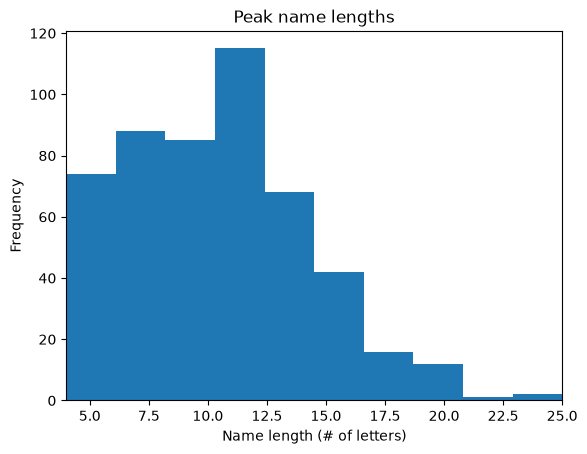

In [11]:
df.pkname.str.len().plot(kind="hist")
plt.title("Peak name lengths")
plt.xlabel("Name length (# of letters)")
plt.xlim((df.pkname.str.len().min(), df.pkname.str.len().max()))
plt.show()

In [12]:
assert df.pkname.is_unique

Notes:
- Peak names adhere to a loose format (start with a letter, followed by alphanumerical characters, spaces, and/or dashes only)
- There are no significant outliers when it comes to name length
- Peak names are unique across the dataset

In [13]:
df.pkname2.value_counts(ascending=False)[:15]

pkname2
Twins                         2
Junction Peak                 2
Tent Peak                     2
Amai Dablang                  1
Amphu Gyabien                 1
Annapurna Dakshin, Moditse    1
Morimoto                      1
Damodar Himal                 1
Changla Himal                 1
Peak 23                       1
Chobutse, Tsoboje             1
Tsolatse, Jobo Lhaptshan      1
Chulu East                    1
Chugimago                     1
Cross Peak                    1
Name: count, dtype: int64

Notes:
- the __pkname2__ column (local names) contains non-atomic, comma-separated values for peaks with multiple local names
- certain peaks share the same local name (many-to-many relationship)
- including local names in a normalized Silver layer will require the creation of two dedicated tables

In [14]:
df.location.nunique()

421

In [15]:
df.location.isna().sum()

np.int64(1)

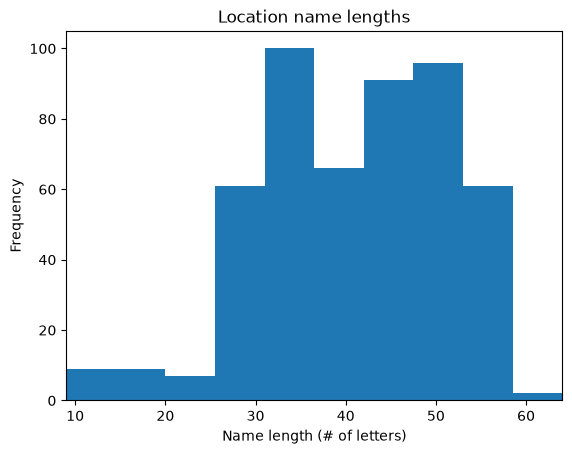

In [16]:
df.location.str.len().plot(kind="hist")
plt.title("Location name lengths")
plt.xlabel("Name length (# of letters)")
plt.xlim((df.location.str.len().min(), df.location.str.len().max()))
plt.show()

Notes:
- __location__ has high cardinality (421) relative to dataset size (503)
- one peak does not have an associated entry for __location__
- no significant outliers in __location__ name lengths
- location names are less structured then peak names (non-alphabetical characters)

In [17]:
print(df.trekyear.dtype)

str


In [18]:
print(df.trekyear.value_counts())

trekyear
1978    20
2002    10
20       1
Name: count, dtype: int64


In [19]:
df.trekyear.isna().mean()

np.float64(0.9383697813121272)

Notes:
- __trekyear__ column has almost all missing values
- non-missing entries are all numerical and should be converted to integer

In [20]:
print(f"Percentage of missing values: {df.restrict.isna().mean():.3f}")
list(df.restrict.unique()[:10])

Percentage of missing values: 0.400


[nan,
 'Opened in 2002',
 'Requires permit for Annapurna I',
 'Opened in 2014',
 'Converted to trekking peak in 2002',
 "One permit for Churen Himal's three summits",
 'Peak entirely within China',
 'Opened in 2003',
 'Opened in 1997',
 'Requires permit for Gimmigela Chuli']

In [21]:
print(f"Percentage of missing values: {df.refermemo.isna().mean():.3f}")
list(df.refermemo.unique()[:10])

Percentage of missing values: 0.962


[nan,
 'Dyhrenfurth history 1950-1977 (MM 58:44-47 Nov 1977)',
 'Dyhrenfurth history 1960-1976 (MM 51:36-37 Sep 1976)',
 'History 1982-1998 (High 198:42 May 1999)   ',
 'Dyhrenfurth history 1950-1978 (MM 60:40-42 Mar 1978)',
 'Dyhrenfurth history 1952-1978 (MM 63:32-36 Sep 1978)',
 'Dyhrenfurth history 1921-1980 (MM 76:30-39 Nov 1980)',
 'High 226:64 Sep 2001\r\n',
 'History 1994-97 (High 179:17-18 Oct 1997)  ',
 'Dyhrenfurth history 1951-1976 (MM 48:28-29 Mar 1976)']

In [22]:
print(f"Percentage of missing values: {df.peakmemo.isna().mean():.3f}")
list(df.peakmemo.unique()[:10])

Percentage of missing values: 0.016


['Other map altitudes:\r\n   6814m - HMG-MT, HMG-Finn, Shangri La \r\n   6828m - NGS/Washburn Everest, Kielkowski\r\n   6856m - Nepa, Schneider, Japan MMW\r\n\r\nAltitude milestones on Ama Dablam:\r\n\r\n   5950m - Yellow Tower\r\n   6050m - Grey Tower\r\n   6150m - Mushroom Ridge\r\n   6600m - Avalanche site',
 'Other map altitudes:\r\n   5630m - HMG-Finn, Nepa, Shangri La\r\n   5647m - HMG-MT, NGS/Washburn Everest, Kielkowski\r\n   5650m - Schneider, Japan MMW',
 'Other map altitudes:\r\n   8091m - HMG-MT, HMG-Finn, Nepa, Shangri La, Schneider, Japan MMW, Leomann',
 'Other map altitudes:\r\n   7937m - HMG-MT, HMG-Finn, Nepa, Shangri La, Schneider, Japan MMW, Leomann',
 'Other map altitudes:\r\n   7555m - HMG-MT, HMG-Finn, Nepa, Shangri La, Schneider, Japan MMW, Leomann',
 'Other map altitudes:\r\n   7525m - HMG-MT, HMG-Finn, Nepa, Shangri La, Schneider, Japan MMW, Leomann',
 'Other map altitudes:\r\n   8000m - Leomann',
 'Other map altitudes:\r\n   8013m - HMG-Finn\r\n   8051m - Leom

In [23]:
print(f"Percentage of missing values: {df.photomemo.isna().mean():.3f}")
list(df.photomemo.unique()[:10])

Percentage of missing values: 0.845


['W Face (High 126:5 May 1993)\r\nSE Face (High 144:38 Nov 1994)\r\nNW Face (High 167:66 Jul 1996)\r\nNE Face (High 218:77 Jan 2001)\r\nNW Face (AAJ 71:6 1997) (Slovene 1996 route) \r\nSE Face (AAJ 69:240 1995)\r\nSW Side (AAJ 64:225 1990)\r\nNE Face (AAJ 58:236 1984, 60:222 1986, 61:33 1987)\r\nW Face (AAJ 61:229 1987) (various routes)\r\nW Side (AAJ 57:1 1983)\r\nS Ridge/SW Face (AAJ 53:450 1980)',
 nan,
 'S Face (High 122:3 Jan 1993) (Beghin accident)\r\nN Face (High 205:72 Dec 1999)\r\nN Side (MM 88:41 Nov 1982)\r\nNW Face (MM 58:46 Nov 1977)\r\nS Face (MM 58:46 Nov 1977)\r\nS Face (MM 12:20 Nov 1970) (Bonington route)\r\nW Face (AAJ 66:220 1992) (various routes)',
 'N Face (MM 51:36 Sep 1976)',
 'S Side (MM 125:11 Jan 1989)\r\nSW Face (MM 71:13 Jan 1980)\r\nS Buttress (AAJ 58:249 1984)\r\nW Face (AAJ 53:60 1979)\r\nSW Face (High 228:80 Nov 2001)  ',
 'SW Pillar (High 198:40 May 1999) \r\nSW Side (AAJ 73:367 1999)',
 'N Side (MM 88:41 Nov 1982)',
 'S Face (High 155:9 Oct 1995)\r\nS

Notes:
- columns __restrict__, __photomemo__, __refermemo__, and __peakmemo__ contain free-form unstructured values
- if at all possible, extracting relevant features for analysis would require extensive processing
- given the above, __these variables will be ommitted from the data models__

### Numeric variables
To assess the cleanliness of numeric variables, I mainly focus on prevalence of missing values, distribution and outlier detection. The aim is to make that values are present and within an expected range.

In the case of the Peaks dataset, several numerical columns merely represent lookup indices for external lookup tables. These will be treated as catefgorical variables in data models.

In [24]:
df.select_dtypes(include=["number"]).head()

,heightm,heightf,himal,region,phost,pstatus,pseason
0,6814,22356,12,2,1,2,1
1,5630,18471,12,2,1,2,1
2,8091,26545,1,5,1,2,1
3,7937,26040,1,5,1,2,1
4,7555,24787,1,5,1,2,1


In [25]:
df.select_dtypes(include=["number"]).isna().sum()

heightm    0
heightf    0
himal      0
region     0
phost      0
pstatus    0
pseason    0
dtype: int64

Notes:
- the raw dataset contains 7 numeric variables with no missing values
- 5 of these variables are foreign key references to static mappings provided in the documentation
- the other 2 variables both represent peak height expressed using the imerial and metric systems

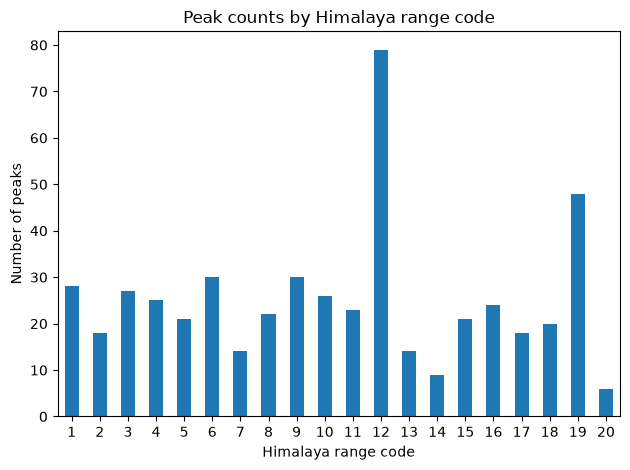

In [26]:
himal_counts = df["himal"].value_counts().sort_index()
himal_counts.plot(kind="bar")
plt.title("Peak counts by Himalaya range code")
plt.xlabel("Himalaya range code")
plt.ylabel("Number of peaks")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

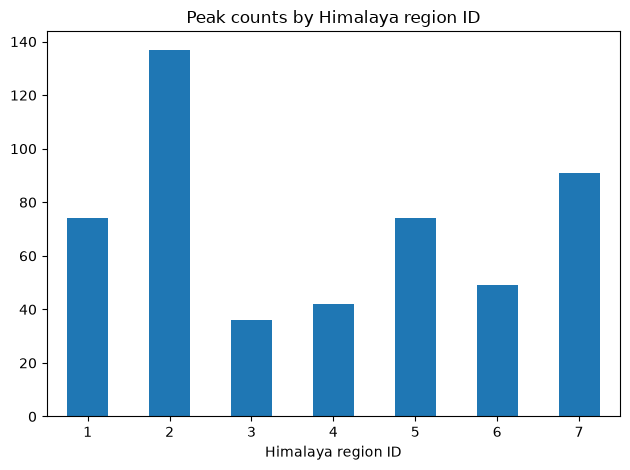

In [27]:
region_counts = df["region"].value_counts().sort_index()
region_counts.plot(kind="bar")
plt.title("Peak counts by Himalaya region ID")
plt.xlabel("Himalaya region ID")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

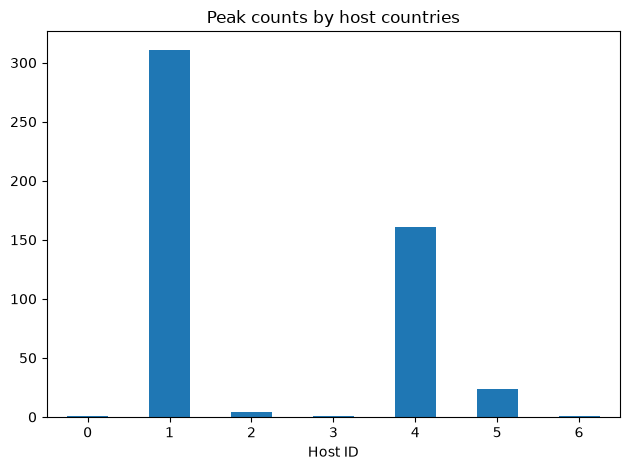

In [28]:
host_counts = df["phost"].value_counts().sort_index()
host_counts.plot(kind="bar")
plt.title("Peak counts by host countries")
plt.xlabel("Host ID")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [29]:
df["climbed"] = df.pstatus == 2

In [30]:
df.pstatus.value_counts(normalize=True)

pstatus
2    0.767396
1    0.232604
Name: proportion, dtype: float64

In [31]:
df.climbed.mean()

np.float64(0.7673956262425448)

- __pstatus__ is a binary variable flagging whether a peak has been climbed, and should be converted to boolean

In [32]:
e = .001
ratios = df.heightm / df.heightf
assert (ratios.max() - ratios.min()) < e

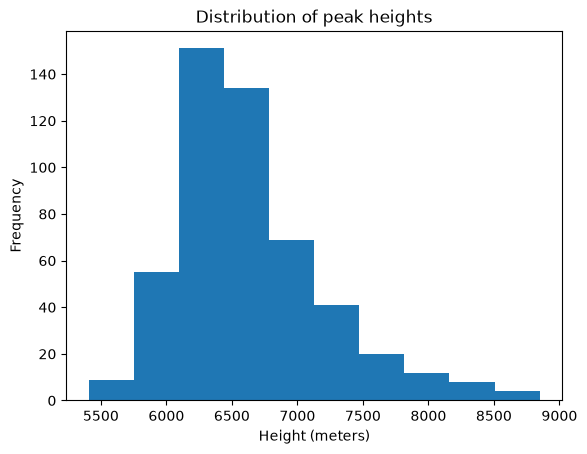

In [33]:
df.heightm.plot(kind="hist")
plt.title("Distribution of peak heights")
plt.xlabel("Height (meters)")
plt.show()

Notes:
- the metric-to-imperial conversion rate is consistent
- there are no suspicious outliers in the peak heights

### Boolean variables

In [34]:
df.select_dtypes(include=[bool]).head()

,open,unlisted,trekking,climbed
0,True,False,False,True
1,True,False,False,True
2,True,False,False,True
3,True,False,False,True
4,True,False,False,True


In [35]:
df.select_dtypes(include=[bool]).isna().sum()

open        0
unlisted    0
trekking    0
climbed     0
dtype: int64

In [36]:
df.select_dtypes(include=[bool]).mean()

open        0.805169
unlisted    0.127237
trekking    0.065606
climbed     0.767396
dtype: float64

- the dataset contains 3 binary variables, each expressing the state of a peak at a given time
- __each of these variables is susceptible to change and will be modeled as slowly-changing dimensions__

#### Overview of findings
A univariate analysis of the different dataset features has revealed key findings with respective to data modeling:
1. __peakid__ uniquely identifies every peak in the dataset and serves as primary key
2. there is a many-to-many relationship between peaks and local names
3. the raw data wrongly lists __trekyear__ as a string variable and should be numeric
4. the __location__ column has one missing value
5. several unstructured text variables have been identified as irrelevant for the purposes of creating a data warehouse
6. boolean variables to be modeled as slowly changing dimensions

## Normalization

In [37]:
assert df.peakid.notna().all()
assert df.peakid.is_unique

The __peakid__ variable is a valid primary key for the Peaks dataset

In [38]:
print("Most peaks per location:", df.groupby('location').peakid.nunique().max())
print("Most peaks per range:", df.groupby('himal').peakid.nunique().max())
print("Most peaks per region:", df.groupby('region').peakid.nunique().max())

Most peaks per location: 6
Most peaks per range: 79
Most peaks per region: 137


In [39]:
print("Most locations per range:", df.groupby('himal').location.nunique().max())
print("Most ranges per location:", df.groupby('location').himal.nunique().max())

Most locations per range: 64
Most ranges per location: 1


In [40]:
print("Most locations per region:", df.groupby('region').location.nunique().max())
print("Most regions per location:", df.groupby('location').region.nunique().max())

Most locations per region: 113
Most regions per location: 1


In [41]:
print("Most ranges in one region:", df.groupby('region')['himal'].nunique().max())
print("Most regions associated with one range:", df.groupby('himal')['region'].nunique().max())

Most ranges in one region: 5
Most regions associated with one range: 2


In [42]:
print("Most region in one host:", df.groupby('region')['himal'].nunique().max())
print("Most regions associated with one range:", df.groupby('himal')['region'].nunique().max())

Most region in one host: 5
Most regions associated with one range: 2


- one-to-many relationship between location and peaks
- one-to-many relationship between range and location
- from the above, I pose that **there are transitive relationships through nested geographical columns: _peak < location < range_**
- there is a __many-to-many relationship between range and region__

#### LOCATION
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | SERIAL    | PK |
| NAME | TEXT | NOT NULL |

#### RANGE
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | SERIAL    | PK |
| NAME | TEXT | NOT NULL |

#### REGION
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | SERIAL    | PK |
| NAME | TEXT | NOT NULL |

#### PEAK
| NAME    | TYPE | CONSTRAINT |
| -------- | ------- | ------- |
| ID  | SERIAL    | PK |
| NAME | TEXT | NOT NULL |
| LOCATION_ID | INTEGER ||
| RANGE_ID | INTEGER ||
| HEIGHT | INT ||
| CLIMBED | BOOL ||
| OPEN | BOOL ||
| UNLISTED | BOOL ||
| TREKKING | BOOL ||

In [43]:
for col in df.columns:
  print(col)

peakid
pkname
pkname2
location
heightm
heightf
himal
region
open
unlisted
trekking
trekyear
restrict
phost
pstatus
peakmemo
pyear
pseason
pexpid
psmtdate
pcountry
psummiters
psmtnote
refermemo
photomemo
climbed
